 ### **4. Клиенты: повторные покупки через customer_unique_id, RFM, когорты**


In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as st
from sqlalchemy import create_engine
import seaborn as sns

In [24]:
engine = create_engine("postgresql+psycopg2://a111@localhost:5432/olist")

ord = pd.read_sql("""select round(count(*) / count( distinct customer_unique_id) :: numeric, 2) as average_orders_count
from orders_delivered d join customers c
on d.customer_id = c.customer_id""", engine)
print(f'Среднее колво заказов на пользователя: {ord.average_orders_count.iat[0]}')

Среднее колво заказов на пользователя: 1.03


In [25]:
pd.read_sql("""
with base as (SELECT customer_unique_id, count(*) as orders
from orders_delivered d
join customers c
on d.customer_id = c.customer_id
group by customer_unique_id
order by orders desc),

base_1 as (select case when orders >= 3 then '3+' 
    else orders::text end as orders_per_customer,
    count(*) as customers
from base
group by orders_per_customer
order by orders_per_customer)

select orders_per_customer, round(customers / sum(customers) over() * 100, 2) as percentage
from base_1""", engine)

,orders_per_customer,percentage
0,1,97.00
1,2,2.75
2,3+,0.24


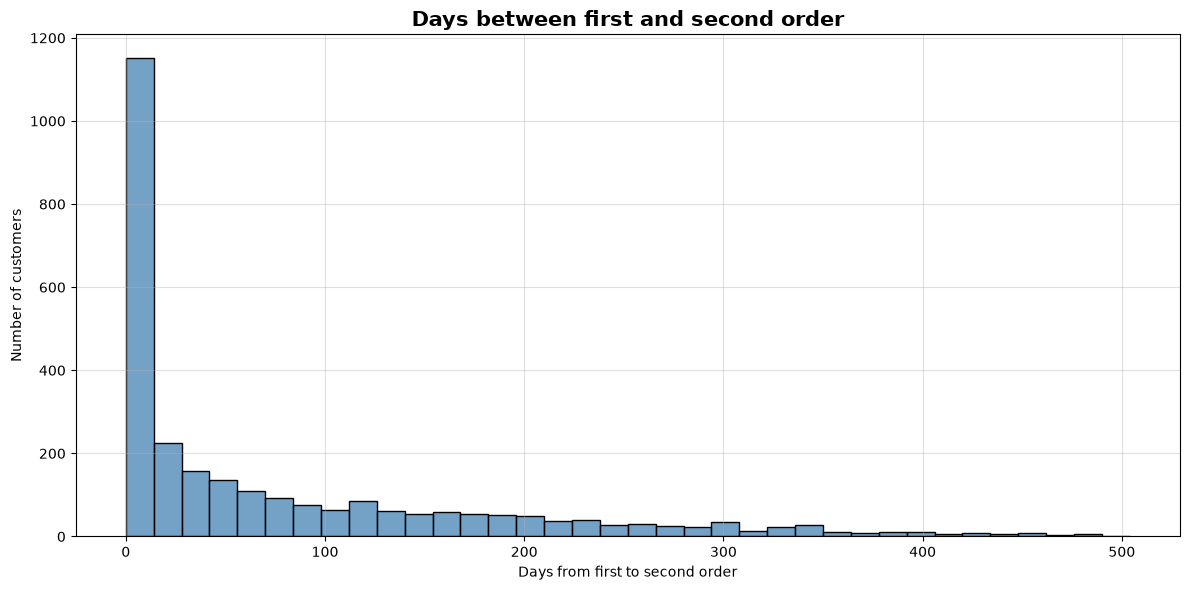

In [ ]:
ret = pd.read_sql("""
with base as (
select customer_unique_id,
    order_purchase_timestamp,
    row_number() over (partition by customer_unique_id order by order_purchase_timestamp) as number_of_purchase
FROM orders_delivered d join customers c on c.customer_id = d.customer_id
where customer_unique_id in (
SELECT customer_unique_id
FROM orders_delivered d join customers c on c.customer_id = d.customer_id
group by customer_unique_id
having count(*) > 1)),

base_1 as (
select customer_unique_id,
MAX(CASE WHEN number_of_purchase = 1 THEN order_purchase_timestamp END) AS first_order_time, 
MAX(CASE WHEN number_of_purchase = 2 THEN order_purchase_timestamp END) AS second_order_time FROM base
GROUP BY customer_unique_id)

select second_order_time::date - first_order_time::date as return_time
from base_1""", engine)

plt.figure(figsize=(12, 6))
sns.histplot(data=ret, x="return_time", binwidth=14, binrange=(0, 504),
             color="steelblue", edgecolor="black")
plt.title("Days between first and second order", fontsize=15, weight="bold")
plt.xlabel("Days from first to second order")
plt.ylabel("Number of customers")
plt.grid(alpha=0.4)
plt.tight_layout()
plt.savefig("../images/days_to_return_distr.png", dpi=150, bbox_inches="tight")
plt.show()

In [27]:
first = pd.read_sql("""
    WITH o AS (
        SELECT c.customer_unique_id,
               d.order_delivered_customer_date::date > d.order_estimated_delivery_date::date AS is_late,
               ROW_NUMBER() OVER (PARTITION BY c.customer_unique_id
                                  ORDER BY d.order_purchase_timestamp) AS rn,
               COUNT(*) OVER (PARTITION BY c.customer_unique_id) AS total_orders
        FROM orders_delivered d
        JOIN customers c ON c.customer_id = d.customer_id
    )
    SELECT CASE WHEN is_late THEN 'late' ELSE 'on time' END AS first_order,
           COUNT(*) AS customers,
           ROUND(100.0 * AVG((total_orders >= 2)::int), 2)::float AS repeat_pct
    FROM o
    WHERE rn = 1
    GROUP BY 1
""", engine)

first

,first_order,customers,repeat_pct
0,late,6356,2.58
1,on time,86740,3.03


In [37]:
print(f'75% пользователей возвращаются в течение {ret.return_time.quantile(0.75)} дней')
print(f'{round((ret[ret.return_time == 0].count() / ret.count()).iat[0] * 100, 2)}% повторных заказов совершены в тот же день')

75% пользователей возвращаются в течение 125.0 дней
29.65% повторных заказов совершены в тот же день


*Клиент определяется по `customer_unique_id`. Считаются доставленные заказы за период янв 2017 – авг 2018.*

**Сколько заказов делает клиент**
- В среднем **1,03 заказа** на клиента.
- **97,0%** клиентов купили один раз, 2,75% дважды, 0,24% три раза и больше. Доля повторных покупателей около **3%**.
- Для маркетплейса это очень низкое удержание: выручка держится почти целиком на привлечении новых клиентов.

**Через сколько возвращаются**
- Медиана срока между первым и вторым заказом: 29 дней, у 75% вернувшихся второй заказ в течение 125 дней.
- 29% повторных заказов сделаны в тот же день: скорее докупка, чем возврат.
- Распределение растянуто: часть клиентов возвращается только через год.

**Доставка и повторная покупка**

| Первый заказ | Клиентов | Доля повторных |
|---|---|---|
| доставлен с опозданием | 6 356 | 2,58% |
| доставлен вовремя | 86 740 | 3,03% |

- У клиентов, чей первый заказ опоздал, доля повторных покупок ниже на 0,45 п.п. (относительно примерно на 15%).

**Ограничения:** период наблюдения около 20 месяцев, поэтому доля повторных покупок занижена (клиенты, купившие в последние месяцы, не успели вернуться).

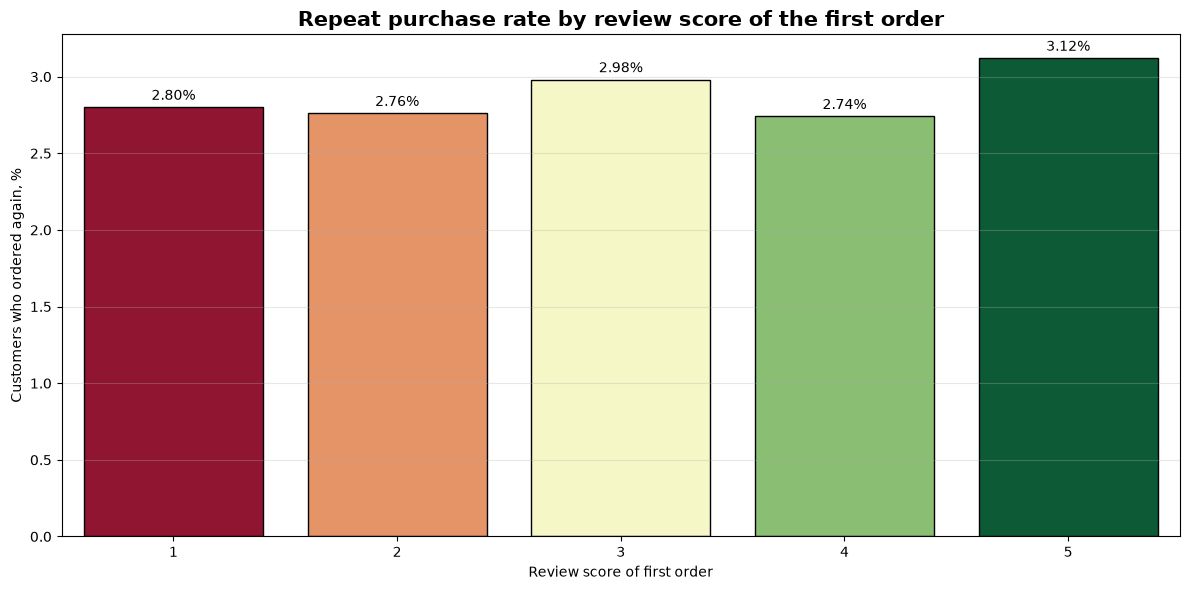

In [54]:
df = pd.read_sql("""
    WITH o AS (
        SELECT c.customer_unique_id,
               d.order_id,
               ROW_NUMBER() OVER (PARTITION BY c.customer_unique_id
                                  ORDER BY d.order_purchase_timestamp) AS rn,
               COUNT(*) OVER (PARTITION BY c.customer_unique_id)       AS total_orders
        FROM orders_delivered d
        JOIN customers c ON c.customer_id = d.customer_id
    )
    SELECT r.review_score,
           COUNT(*)                                             AS customers,
           ROUND(100.0 * AVG((o.total_orders >= 2)::int), 2)::float AS repeat_pct
    FROM o
    JOIN order_reviews_clean r ON r.order_id = o.order_id
    WHERE o.rn = 1
    GROUP BY r.review_score
    ORDER BY r.review_score
""", engine)

plt.figure(figsize=(12, 6))
ax = sns.barplot(data=df, x="review_score", y="repeat_pct",
                 hue="review_score", palette="RdYlGn", legend=False,
                 order=[1, 2, 3, 4, 5], edgecolor="black")
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f%%", padding=3)
plt.title("Repeat purchase rate by review score of the first order", fontsize=15, weight="bold")
plt.xlabel("Review score of first order")
plt.ylabel("Customers who ordered again, %")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("../images/repeat_by_first_score.png", dpi=150, bbox_inches="tight")
plt.show()

### Оценка первого заказа и повторная покупка

- Доля клиентов, сделавших повторный заказ, почти не зависит от оценки первого заказа: во всех группах она составляет около 2,8–3,1%.
- Даже клиенты, поставившие «1», возвращаются примерно так же часто, как клиенты с оценкой «4». Лучшая доля у оценки «5», но разница небольшая.
- Вместе с результатом по доставке (2,58% против 3,03%) это показывает, что качество сервиса слабо объясняет низкое удержание. Причины стоит искать в других факторах, например в типе товаров и источнике клиентов.
- **Ограничения:** клиентов с оценками 1–2 мало, поэтому их доли менее устойчивы; в анализ вошли только заказы с отзывом.

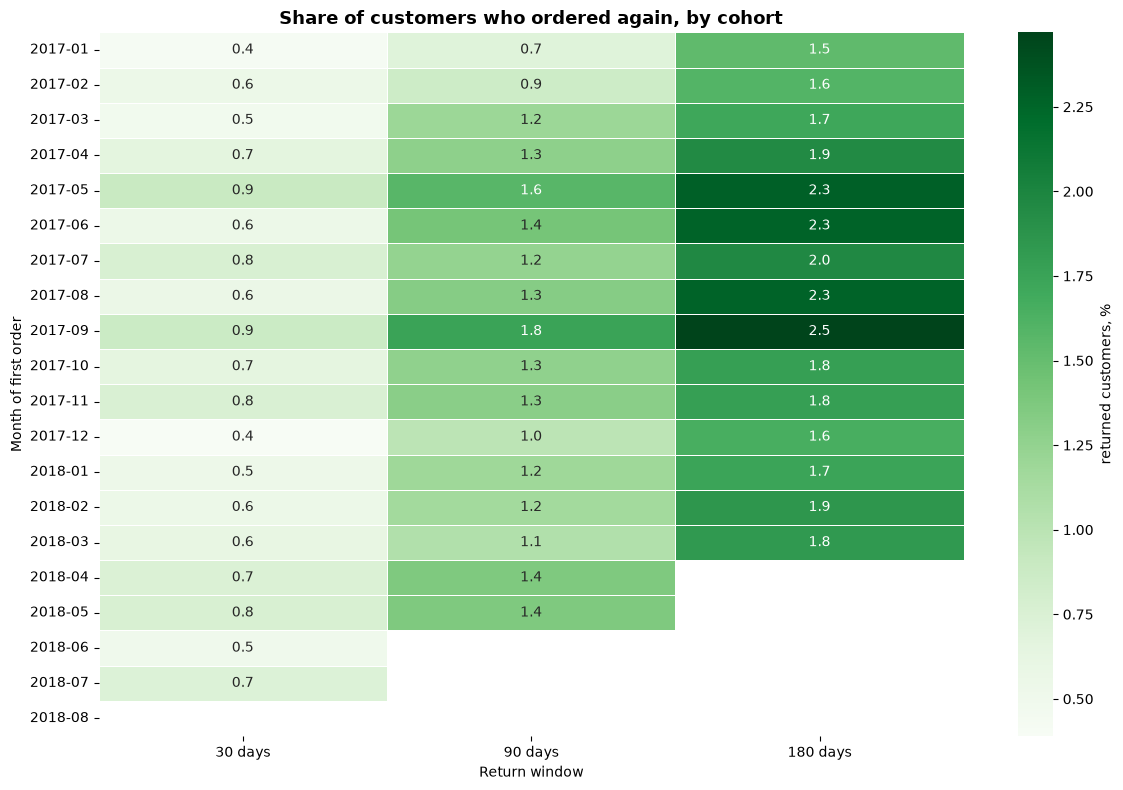

In [62]:
coh = pd.read_sql("""
    with o as (
        select c.customer_unique_id,
               d.order_purchase_timestamp as ts,
               row_number() over (partition by c.customer_unique_id
                                  order by d.order_purchase_timestamp) as rn
        from orders_delivered d
        join customers c on c.customer_id = d.customer_id
    ),
    pairs as (
        select f.customer_unique_id,
               date_trunc('month', f.ts)::date as cohort,
               f.ts as first_ts,
               s.ts as second_ts
        from o f
        left join o s on s.customer_unique_id = f.customer_unique_id and s.rn = 2
        where f.rn = 1
    ),
    last_day as (
        select max(order_purchase_timestamp) as last_ts from orders_delivered
    )
    select cohort,
           count(*) as customers,
           round(100.0 * avg(coalesce(second_ts::date - first_ts::date between 1 and 30, false)::int)
                 filter (where first_ts <= last_ts - interval '30 days'), 2)::float as ret_30,
           round(100.0 * avg(coalesce(second_ts::date - first_ts::date between 1 and 90, false)::int)
                 filter (where first_ts <= last_ts - interval '90 days'), 2)::float as ret_90,
           round(100.0 * avg(coalesce(second_ts::date - first_ts::date between 1 and 180, false)::int)
                 filter (where first_ts <= last_ts - interval '180 days'), 2)::float as ret_180
    from pairs, last_day
    group by cohort
    order by cohort
""", engine)

hm = coh.set_index(coh["cohort"].astype(str).str[:7])[["ret_30", "ret_90", "ret_180"]]
hm.columns = ["30 days", "90 days", "180 days"]
plt.figure(figsize=(12, 8))
sns.heatmap(hm, annot=True, fmt=".1f", cmap="Greens", linewidths=0.5,
            cbar_kws={"label": "returned customers, %"})
plt.title("Share of customers who ordered again, by cohort", fontsize=13, weight="bold")
plt.xlabel("Return window")
plt.ylabel("Month of first order")
plt.tight_layout()
plt.savefig("../images/cohort_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

### Когорты: доля вернувшихся по месяцу первой покупки

*Возвратом считается заказ в другой день после первого. Для каждого окна учитываются только когорты, у которых оно уже полностью прошло, поэтому у свежих когорт часть клеток пустая.*

- **Возвраты редки в любом окне.** В течение 30 дней возвращается 0,4–0,9% клиентов (в среднем около 0,65%), в течение 90 дней 0,7–1,8% (около 1,25%), в течение 180 дней 1,5–2,5% (около 1,9%). Это простое среднее по когортам.
- **Возвраты копятся медленно.** От 30 до 180 дней доля вырастает всего на 1–1,5 п.п. Резкого всплеска повторных покупок после первого заказа нет.
- **Различия между когортами небольшие.** Лучше остальных выглядит когорта сентября 2017 (0,9% / 1,8% / 2,5%), хорошо также май–август 2017 (2,0–2,3% за 180 дней). Слабее всего январь 2017 (0,4% / 0,7% / 1,5%) и декабрь 2017 (0,4% / 1,0% / 1,6%).
- **Тренда нет.** Когорты середины 2017 года чуть лучше когорт начала 2018 (за 180 дней 2,0–2,5% против 1,7–1,9%), но разница около 0,5 п.п., и я не считаю её выводом. Улучшения удержания со временем незаметно.
- **Black Friday не ухудшила удержание.** Когорта ноября 2017 (0,8% / 1,3% / 1,8%) находится на уровне соседних месяцев, так что клиенты, пришедшие в период распродаж, возвращаются не реже обычных.
- **Вывод:** удержание низкое во всех когортах и почти не меняется, поэтому рост бизнеса в этот период шёл за счёт новых клиентов, а не повторных покупок.

In [ ]:
value = pd.read_sql("""
    with customer_revenue as (
        select c.customer_unique_id,
               count(distinct d.order_id) as orders,
               sum(p.payment_value)       as revenue
        from orders_delivered d
        join customers c      on c.customer_id = d.customer_id
        join order_payments p on p.order_id = d.order_id
        group by c.customer_unique_id
    )
    select case when orders > 1 then 'repeat customers'
                else 'one-time customers' end                              as customer_type,
           count(*)                                                        as customers,
           round(100.0 * count(*) / sum(count(*)) over (), 2)::float       as customers_share_pct,
           round(sum(revenue)::numeric, 0)::float                          as revenue,
           round(100.0 * sum(revenue) / sum(sum(revenue)) over (), 2)::float as revenue_share_pct,
           round(avg(revenue)::numeric, 2)::float                          as revenue_per_customer
    from customer_revenue
    group by customer_type
""", engine)

value

,customer_type,customers,customers_share_pct,revenue,revenue_share_pct,revenue_per_customer
0,repeat customers,2789,3.0,860755.0,5.6,308.62
1,one-time customers,90307,97.0,14513742.0,94.4,160.72


### Ценность повторных клиентов

- Повторные клиенты составляют 3,0% базы и приносят 5,6% выручки: почти вдвое больше своей доли.
- Выручка на одного повторного клиента в 1,9 раза выше, чем на разового (308,62 против 160,72 R$). Это меньше двух, хотя у них минимум два заказа, поэтому дело в частоте покупок, а не в размере чека.
- 94,4% выручки приходит от клиентов, которые купили один раз. Бизнес зависит от постоянного притока новых покупателей.
- Метрика: сумма платежей (с доставкой) по доставленным заказам за период янв 2017 – авг 2018. Доля повторных клиентов занижена, потому что окно наблюдения около 20 месяцев.

### **5. Продавцы и товары: рейтинг, концентрация выручки**

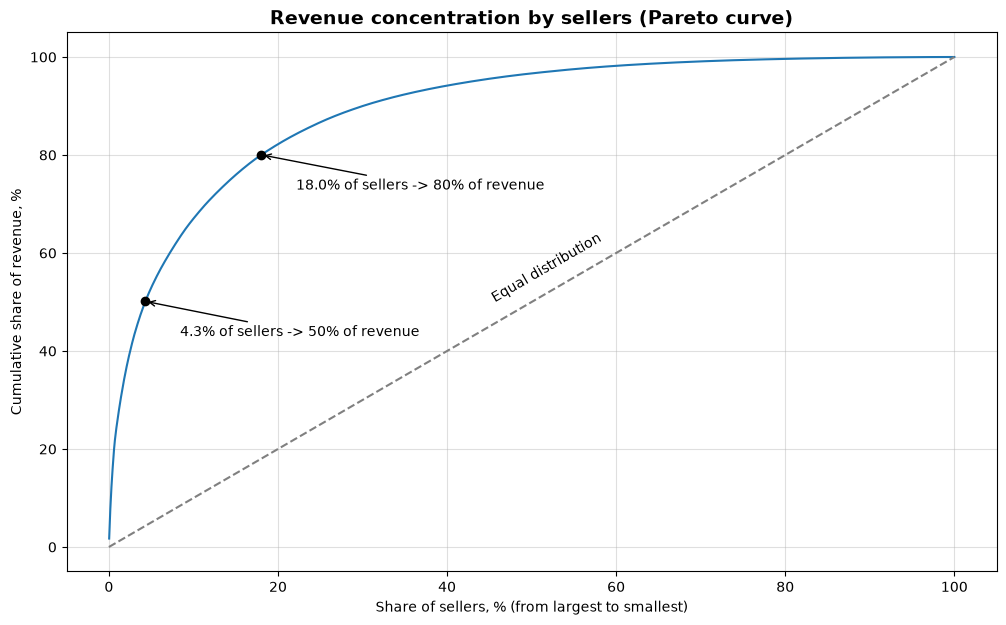

In [120]:
sellers = pd.read_sql("""
with base as (select revenue / sum(revenue) over() * 100.0 as pct_in_total_revenue, count(*) over() as total_sellers
from
(select i.seller_id,
    sum(i.price) as revenue
from orders_delivered d join order_items i on d.order_id = i.order_id
group by seller_id
order by revenue desc) q)

select row_number() over (order by pct_in_total_revenue desc) / total_sellers :: numeric * 100.0 as rank_pct,
    pct_in_total_revenue,
    sum(pct_in_total_revenue) over(order by pct_in_total_revenue desc rows between unbounded preceding and current row) as cumulative_pct,
    total_sellers
from base
""", engine)

plt.figure(figsize=(12,7))
plt.grid(alpha=0.4)
plt.plot(sellers.rank_pct, sellers.cumulative_pct)
plt.plot([0, 100], [0, 100], color="gray", linestyle="--", label="equal distribution")
plt.text(45, 50, 'Equal distribution', rotation=30, fontsize=10,)
plt.xlabel("Share of sellers, % (from largest to smallest)")
plt.ylabel("Cumulative share of revenue, %")
plt.title("Revenue concentration by sellers (Pareto curve)", fontsize=14, weight="bold")

for target in (50, 80):
    idx = (sellers["cumulative_pct"] >= target).idxmax()

    x = sellers.loc[idx, "rank_pct"]
    y = sellers.loc[idx, "cumulative_pct"]

    plt.scatter(x, y, color="black", zorder=5)
    plt.annotate(
        f"{x:.1f}% of sellers -> {target}% of revenue",
        (x, y),
        xytext=(25, -25),
        textcoords="offset points",
        arrowprops=dict(arrowstyle="->", color="black")
    )
plt.savefig("../images/sellers_pareto.png", dpi=150, bbox_inches="tight")
plt.show()

### Анализ концентрации выручки среди продавцов

- **4,3% крупнейших продавцов** обеспечивают 50% всей выручки маркетплейса.
- **18% продавцов** генерируют 80% выручки, что соответствует принципу Парето (80/20).
- Значительное отклонение кривой от линии равномерного распределения указывает на **высокую концентрацию выручки** среди небольшой группы продавцов.
- Остальные **82% продавцов формируют лишь 20% выручки**, что свидетельствует о существенной неравномерности продаж.

**Вывод:** выручка маркетплейса сильно зависит от небольшой группы крупнейших продавцов. Это создаёт потенциальные риски при их уходе с платформы. Поэтому важно уделять внимание удержанию ключевых продавцов и развитию менее крупных участников.

In [149]:

sells = pd.read_sql("""
WITH seller_orders AS (
    SELECT
        i.seller_id,
        i.order_id,
        SUM(i.price) AS revenue_without_freight,
        SUM(i.price + i.freight_value) AS revenue_with_freight,
        MAX(
            (i.shipping_limit_date < d.order_delivered_carrier_date)::int
        ) AS carrier_late,
        (MAX(d.order_estimated_delivery_date) <
         MAX(d.order_delivered_customer_date))::int AS customer_late
    FROM order_items i
    JOIN orders_delivered d
        ON d.order_id = i.order_id
    WHERE d.order_delivered_carrier_date IS NOT NULL
    GROUP BY i.seller_id, i.order_id
),
reviews AS (
    SELECT
        order_id,
        AVG(review_score) AS review_score
    FROM order_reviews
    GROUP BY order_id
)
SELECT
    SUM(so.revenue_without_freight) AS revenue_without_freight,
    SUM(so.revenue_with_freight) AS revenue_with_freight,
    COUNT(*) AS orders,
    SUM(so.revenue_without_freight) / count(*) as AOV,
    AVG(so.carrier_late) AS carrier_late_share,
    AVG(so.customer_late) AS customer_late_share,
    AVG(r.review_score) AS avg_review_score
FROM seller_orders so
LEFT JOIN reviews r
    ON r.order_id = so.order_id
GROUP BY so.seller_id
ORDER BY orders DESC
""", engine)

sells


,revenue_without_freight,revenue_with_freight,orders,aov,carrier_late_share,customer_late_share,avg_review_score
0,120702.83,148050.94,1819,66.356696,0.005498,0.064321,3.979501
1,196882.12,231220.43,1772,111.107291,0.086907,0.110045,3.853109
2,101090.96,125936.99,1651,61.230139,0.007268,0.061175,4.151994
3,106655.71,141712.94,1399,76.237105,0.108649,0.105790,4.140603
4,159816.87,184706.78,1311,121.904554,0.045004,0.076278,4.178544
...,...,...,...,...,...,...,...
2940,179.90,282.47,1,179.900000,0.000000,0.000000,5.000000
2941,41.90,49.45,1,41.900000,0.000000,0.000000,5.000000
2942,599.50,674.83,1,599.500000,0.000000,0.000000,5.000000
2943,59.90,82.03,1,59.900000,0.000000,0.000000,5.000000


In [150]:

import pandas as pd
from scipy.stats import spearmanr

df = sells[sells['orders'] >= 50].copy()

hypotheses = {
    'Orders vs Carrier Late':
        ('orders', 'carrier_late_share'),
    'Delivery Late vs Review Score':
        ('customer_late_share', 'avg_review_score'),
    'AOV vs Delivery Late':
        ('aov', 'customer_late_share'),
    'Carrier Late vs Delivery Late':
        ('carrier_late_share', 'customer_late_share')
}

results = []

for name, (x, y) in hypotheses.items():
    data = df[[x, y]].dropna()

    if len(data) < 3 or data[x].nunique() < 2 or data[y].nunique() < 2:
        continue

    rho, p_value = spearmanr(data[x], data[y])

    results.append({
        'Hypothesis': name,
        'N_sellers': len(data),
        'Spearman_rho': round(rho, 3),
        'p_value': round(p_value, 4)
    })

corr_results = pd.DataFrame(results)
corr_results


,Hypothesis,N_sellers,Spearman_rho,p_value
0,Orders vs Carrier Late,424,0.046,0.3474
1,Delivery Late vs Review Score,424,-0.464,0.0000
2,AOV vs Delivery Late,424,0.029,0.5464
3,Carrier Late vs Delivery Late,424,0.430,0.0000


### Корреляционный анализ метрик продавцов

Для выявления зависимостей между показателями продавцов был проведён корреляционный анализ с использованием **коэффициента Спирмена**.

В исследование включены **424 продавца**, имеющих не менее 50 заказов. Статистическая значимость проверялась на уровне $\alpha = 0.05$.

#### Результаты

| Показатели | Spearman ρ | p-value |
|---|---:|---:|
| Количество заказов / Доля поздних отправок | 0.046 | 0.3474 |
| Доля поздних доставок / Средняя оценка | -0.464 | < 0.0001 |
| AOV / Доля поздних доставок | 0.029 | 0.5464 |
| Доля поздних отправок / Доля поздних доставок | 0.430 | < 0.0001 |

#### Основные выводы

- **Количество заказов и опоздания при отправке:** корреляция практически отсутствует (ρ = 0.046, p = 0.3474). Статистически значимой монотонной зависимости между объёмом заказов продавца и соблюдением сроков отправки не обнаружено.
- **Опоздания доставки и оценки:** обнаружена умеренная отрицательная корреляция (ρ = -0.464, p < 0.0001). Продавцы с более высокой долей просроченных доставок, как правило, получают более низкие оценки покупателей.
- **AOV и опоздания доставки:** корреляция практически отсутствует (ρ = 0.029, p = 0.5464). Статистически значимой монотонной связи между средним чеком и долей просроченных доставок не выявлено.
- **Опоздания при отправке и доставке:** обнаружена умеренная положительная корреляция (ρ = 0.430, p < 0.0001). Продавцы, чаще нарушающие сроки отправки, также характеризуются более высокой долей просроченных достав